In [15]:
!pip install seaborn
!pip install imbalanced-learn


[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


   ---------------------------------------- 0.0/236.1 kB ? eta -:--:--
   ------------------- -------------------- 112.6/236.1 kB 2.2 MB/s eta 0:00:01
   ---------------------------------------  235.5/236.1 kB 2.9 MB/s eta 0:00:01
   ---------------------------------------- 236.1/236.1 kB 2.4 MB/s eta 0:00:00



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

# Configuración profesional de gráficas
sns.set_theme(style="whitegrid", context="paper", font_scale=1.2)
plt.rcParams['figure.figsize'] = (10, 6)

# Modelos y Evaluación
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import make_scorer, f1_score
from sklearn.impute import SimpleImputer

# Pipelines e Imblearn
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

import warnings
warnings.filterwarnings('ignore')

1. Módulo de Carga y Preprocesamiento Seguro

Encapsulamos la lógica de ingesta en una función para garantizar inmutabilidad y facilitar la reproducibilidad.

In [29]:
import sys, warnings
import pandas as pd
import numpy as np
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

def cargar_datos_entrenamiento(ruta_base=ROOT / 'data/processed'):
    """
    Carga, integra y filtra los datos respetando la partición congelada.
    Retorna la matriz de características (X) y el vector objetivo (y) limpios.
    """
    try:
        df_feat = pd.read_csv(f'{ruta_base}/features_frutos.csv')
        df_ind = pd.read_csv(f'{ruta_base}/indice_frutos.csv')
        df_part = pd.read_csv(f'{ruta_base}/particion.csv')
        
        # Integración relacional
        df = df_feat.merge(df_ind, on='id_fruto', suffixes=('', '_ref'))
        df = df.merge(df_part, on='id_fruto')
        
        # Aislamiento de la partición de entrenamiento
        df_train = df[df['subset'] == 'train'].copy()
        
        # Identificación estricta de columnas de fuga de información (data leakage)
        cols_fuga = [
            'id_fruto', 'lote', 'fecha', 'lote_ref', 'fecha_ref', 'calibre_mm_ref', 
            'categoria_ref', 'color_panel', 'severidad_defecto_panel', 
            'vistas_presentes', 'n_vistas', 'vistas_faltantes', 'completo', 
            'origen', 'subset', 'n_vistas_validas', 'frac_seg_ok', 't_extraccion_ms'
        ]
        
        X = df_train.drop(columns=[c for c in cols_fuga if c in df_train.columns])
        y = df_train['categoria_ref']
        
        return X, y
    except FileNotFoundError as e:
        print(f"Error de E/S: Verifique las rutas de los archivos. Detalle: {e}")
        return None, None

X_train, y_train = cargar_datos_entrenamiento()

display(Markdown(f"**Instancias de entrenamiento:** {X_train.shape[0]}"))
display(Markdown(f"**Espacio dimensional (Features):** {X_train.shape[1]}"))

**Instancias de entrenamiento:** 224

**Espacio dimensional (Features):** 32

2. Motor de Evaluación Estructurada (Cross-Validation Engine)

Diseñamos un motor que no solo extrae la media, sino la desviación estándar y los scores crudos por pliegue, fundamentales para pruebas de hipótesis.

In [31]:
def evaluar_experimentos(diccionario_pipelines, X, y, cv_splits=5):
    """
    Ejecuta validación cruzada para un diccionario de modelos/pipelines.
    Retorna un DataFrame de resumen consolidado y un diccionario con los scores crudos.
    """
    cv = StratifiedKFold(n_splits=cv_splits, shuffle=True, random_state=42)
    
    scoring = {
        'f1_macro': make_scorer(f1_score, average='macro'),
        'f1_fabrica': make_scorer(f1_score, labels=['Fabrica'], average=None)
    }
    
    resumen = []
    scores_crudos = {}
    
    for nombre, pipeline in diccionario_pipelines.items():
        res = cross_validate(pipeline, X, y, cv=cv, scoring=scoring, n_jobs=-1)
        
        # Almacenamiento crudo para análisis distributivo
        scores_crudos[nombre] = {
            'f1_macro': res['test_f1_macro'],
            'f1_fabrica': res['test_f1_fabrica']
        }
        
        # Consolidación estadística (Media ± Desviación Estándar)
        resumen.append({
            'Configuración': nombre,
            'CV F1 macro': f"{np.mean(res['test_f1_macro']):.3f} ± {np.std(res['test_f1_macro']):.3f}",
            'CV F1 Fábrica': f"{np.mean(res['test_f1_fabrica']):.3f} ± {np.std(res['test_f1_fabrica']):.3f}",
            'Media_F1_Macro_Num': np.mean(res['test_f1_macro']) # Para ordenamiento interno
        })
        
    df_resumen = pd.DataFrame(resumen).sort_values('Media_F1_Macro_Num', ascending=False)
    df_resumen.drop(columns=['Media_F1_Macro_Num'], inplace=True)
    
    return df_resumen, scores_crudos

3. Ejecución de Experimentos: Baseline y Variantes de Datos

Se declaran los pipelines completos (Imputación + Remuestreo + Clasificador) y se inyectan al motor de evaluación.

In [32]:
# Clasificadores Base
clf_dummy = DummyClassifier(strategy='most_frequent')
clf_knn = KNeighborsClassifier()
clf_gnb = GaussianNB()

# Diccionario unificado de experimentos (Baseline + Variantes V2)
experimentos = {
    # Baselines
    'BASE: Dummy': ImbPipeline([('imputer', SimpleImputer(strategy='mean')), ('clf', clf_dummy)]),
    'BASE: KNN': ImbPipeline([('imputer', SimpleImputer(strategy='mean')), ('clf', clf_knn)]),
    'BASE: GNB (Referencia)': ImbPipeline([('imputer', SimpleImputer(strategy='mean')), ('clf', clf_gnb)]),
    
    # Variantes de Datos centradas en GNB
    'V2_GNB: Sobremuestreo': ImbPipeline([
        ('imputer', SimpleImputer(strategy='mean')),
        ('sampler', RandomOverSampler(random_state=42)),
        ('clf', clf_gnb)
    ]),
    'V2_GNB: Submuestreo': ImbPipeline([
        ('imputer', SimpleImputer(strategy='mean')),
        ('sampler', RandomUnderSampler(random_state=42)),
        ('clf', clf_gnb)
    ])
}

# Ejecución
df_resultados, scores_detallados = evaluar_experimentos(experimentos, X_train, y_train)

display(Markdown("### Tabla 1: Desempeño Consolidado de Modelos y Variantes"))
display(df_resultados)

### Tabla 1: Desempeño Consolidado de Modelos y Variantes

,Configuración,CV F1 macro,CV F1 Fábrica
3,V2_GNB: Sobremuestreo,0.861 ± 0.070,0.912 ± 0.056
2,BASE: GNB (Referencia),0.850 ± 0.099,0.910 ± 0.040
4,V2_GNB: Submuestreo,0.758 ± 0.096,0.829 ± 0.057
1,BASE: KNN,0.465 ± 0.040,0.485 ± 0.092
0,BASE: Dummy,0.128 ± 0.003,0.000 ± 0.000


4. Análisis Distributivo e Inferencia

Las barras simples ocultan la varianza inter-pliegue. Utilizaremos diagramas de caja (boxplots) superpuestos con los puntos de datos (stripplot) para visualizar la superposición del rendimiento y justificar la falta de evidencia estadística reportada.

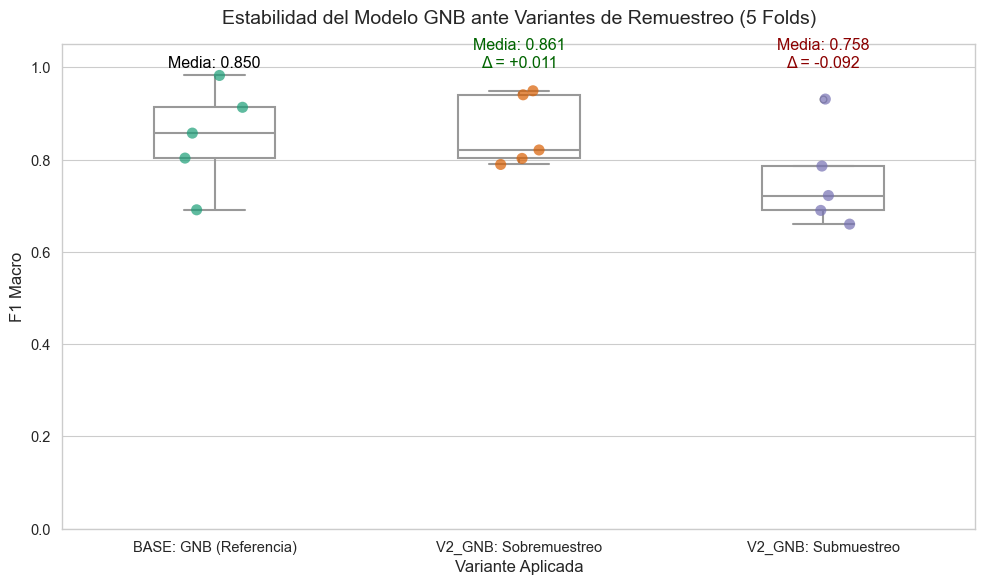

> **Interpretación Analítica:** La alta varianza entre los pliegues de validación cruzada y la superposición de las cajas intercuartílicas indican empíricamente por qué las variantes de remuestreo de datos no logran una mejora estadísticamente demostrable frente al baseline original, alineándose con las conclusiones del reporte general.

In [34]:
# Preparar datos para visualización
data_plot = []
for config, metricas in scores_detallados.items():
    if 'GNB' in config: # Filtramos solo los experimentos relevantes para la variante
        for val in metricas['f1_macro']:
            data_plot.append({'Configuración': config, 'F1 Macro': val})

df_plot = pd.DataFrame(data_plot)

# Generación del gráfico
fig, ax = plt.subplots(figsize=(10, 6))

# Boxplot para distribución + Stripplot para observaciones individuales (pliegues)
sns.boxplot(x='Configuración', y='F1 Macro', data=df_plot, 
            color='white', width=0.4, linewidth=1.5, ax=ax)
sns.stripplot(x='Configuración', y='F1 Macro', data=df_plot, 
              size=8, alpha=0.7, palette='Dark2', jitter=True, ax=ax)

# Formato académico
ax.set_title('Estabilidad del Modelo GNB ante Variantes de Remuestreo (5 Folds)', fontsize=14, pad=15)
ax.set_ylabel('F1 Macro', fontsize=12)
ax.set_xlabel('Variante Aplicada', fontsize=12)
ax.set_ylim(0, 1.05)

# Calcular y mostrar el Delta (Δ) de la media en el gráfico
media_base = np.mean(scores_detallados['BASE: GNB (Referencia)']['f1_macro'])
media_over = np.mean(scores_detallados['V2_GNB: Sobremuestreo']['f1_macro'])
media_under = np.mean(scores_detallados['V2_GNB: Submuestreo']['f1_macro'])

ax.text(0, 1.0, f"Media: {media_base:.3f}", ha='center', color='black')
ax.text(1, 1.0, f"Media: {media_over:.3f}\nΔ = {media_over - media_base:+.3f}", ha='center', color='darkgreen' if media_over >= media_base else 'darkred')
ax.text(2, 1.0, f"Media: {media_under:.3f}\nΔ = {media_under - media_base:+.3f}", ha='center', color='darkgreen' if media_under >= media_base else 'darkred')

plt.tight_layout()
plt.show()

display(Markdown("> **Interpretación Analítica:** La alta varianza entre los pliegues de validación cruzada y la superposición de las cajas intercuartílicas indican empíricamente por qué las variantes de remuestreo de datos no logran una mejora estadísticamente demostrable frente al baseline original, alineándose con las conclusiones del reporte general."))